# IT9002 Lab 6.2: Reading Movie Reviews in Order with Recurrent Networks

**Unit 06: Neural Sequence Models**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, you should be able to:

- Convert reviews into padded sequences of word indices.
- Use Keras to train recurrent networks with word vectors starting from random values and from GloVe vectors.
- Evaluate recurrent networks against a TF-IDF baseline on the same test reviews.
- Calculate the attention weights and the context vector of one decoder step with NumPy.
- Use a saved recurrent network to predict the sentiment of new reviews.

## Data

- **IMDB Large Movie Review Dataset** (Maas et al., 2011), 10,000 reviews of the training split, 5,000 positive and 5,000 negative, with a saved split into 7,000 training, 1,500 validation, and 1,500 test reviews, https://ai.stanford.edu/~amaas/data/sentiment/, released by the authors for research use.

- **GloVe 100d** (Pennington, Socher and Manning, 2014), 400,000 word vectors of 100 dimensions trained on Wikipedia 2014 and Gigaword 5, https://nlp.stanford.edu/projects/glove/, Public Domain Dedication and License v1.0.

- The course file `imdb_sample.csv` (on Moodle).

Training is faster on a GPU runtime. Select **Runtime > Change runtime type > T4 GPU** before running the first cell, since changing the runtime clears its files.

The file `imdb_sample.csv` can be downloaded from Moodle. Download it to your computer, then run the cell below. If the file is already available in the runtime, the cell loads it directly; otherwise, it opens a file-upload dialog.

In [1]:
from pathlib import Path
import pandas as pd

DATA = "imdb_sample.csv"
path = next((p for p in (Path(DATA), Path("data") / DATA) if p.exists()), None)
if path is None:
    from google.colab import files
    files.upload()
    path = Path(DATA)

reviews = pd.read_csv(path)
print(reviews.shape)
reviews.head()

(10000, 4)


,review_id,label,split,text
0,0,negative,train,I rented I AM CURIOUS-YELLOW from my video sto...
1,3,negative,train,This film was probably inspired by Godard's Ma...
2,8,negative,validation,"Who are these ""They""- the actors? the filmmake..."
3,10,negative,validation,It was great to see some of my favorite stars ...
4,12,negative,test,Never cast models and Playboy bunnies in your ...


## Setup

**gensim**, used to download the GloVe vectors, is not always preinstalled in Google Colab. The following cell installs it if it is not available.

In [2]:
import importlib.util, subprocess, sys

if importlib.util.find_spec("gensim") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gensim"], check=True)

Imports the libraries and tools required for the lab and displays the installed versions of **TensorFlow**, **Keras**, and gensim. The lab uses Keras 3.

In [3]:
import re
import string
import gensim
import gensim.downloader as api
import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from keras import layers
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

tf.get_logger().setLevel("ERROR")  # hides TensorFlow warnings about the runtime
pd.set_option("display.max_colwidth", 300)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| gensim", gensim.__version__)

TensorFlow 2.21.0 | Keras 3.15.1 | gensim 4.4.0


## 1. Movie Reviews and the Saved Split

`split_reviews()` returns the texts and the labels of the three sets of the `split` column, with 0 for negative and 1 for positive. The reviews are counted by set and label:

In [4]:
LABELS = ["negative", "positive"]

def split_reviews(reviews):
    parts = {}
    for name in ("train", "validation", "test"):
        part = reviews[reviews.split == name]
        labels = (part.label == "positive").astype(int).to_numpy()
        parts[name] = (part.text.to_numpy(), labels)
    return parts

parts = split_reviews(reviews)
texts_train, y_train = parts["train"]
texts_val, y_val = parts["validation"]
texts_test, y_test = parts["test"]
reviews.groupby(["split", "label"]).size().unstack()

label,negative,positive
split,,
test,750,750
train,3500,3500
validation,750,750


## 2. Word Indices and Padding

The **TextVectorization** layer of Keras lowercases a review, removes its punctuation, splits it into tokens, and converts each token into its word index:

- `max_tokens=10_000`: the size of the vocabulary that `adapt()` constructs from the training reviews, with `''` at index 0 for padding and `[UNK]` at index 1 for tokens outside the vocabulary.

- `output_sequence_length=200`: pads each shorter review with zeros at the end and truncates each longer one after position 200.

The first 6 entries of the vocabulary and the first 8 indices of 2 phrases are displayed:

In [5]:
VOCAB_SIZE = 10_000
SEQUENCE_LENGTH = 200

vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, output_sequence_length=SEQUENCE_LENGTH)
vectorizer.adapt(texts_train)
vocabulary = vectorizer.get_vocabulary()
print([str(word) for word in vocabulary[:6]])
print(vectorizer(["the acting was good", "a slow and boring film"]).numpy()[:, :8])

['', '[UNK]', 'the', 'a', 'and', 'of']
[[  2 109  13  49   0   0   0   0]
 [  3 518   4 365  19   0   0   0]]


`review_lengths()` counts the tokens of each review text after the same lowercasing and removal of punctuation, since the layer's output is already truncated at 200:

- `texts`: the reviews, for example `texts_train`.

The median length, the 90th percentile, and the number of training reviews kept in full or truncated are displayed:

In [6]:
def review_lengths(texts):
    punctuation = re.compile("[%s]" % re.escape(string.punctuation))
    return np.array([len(punctuation.sub("", text.lower()).split()) for text in texts])

lengths = review_lengths(texts_train)
print("median:", np.median(lengths), "| 90th percentile:", np.percentile(lengths, 90))
print("kept in full:", int((lengths <= SEQUENCE_LENGTH).sum()),
      "| truncated:", int((lengths > SEQUENCE_LENGTH).sum()))

median: 172.0 | 90th percentile: 452.0
kept in full: 4166 | truncated: 2834


The three sets are converted into arrays of word indices, and their shapes are displayed:

In [7]:
X_train = vectorizer(texts_train).numpy()
X_val = vectorizer(texts_val).numpy()
X_test = vectorizer(texts_test).numpy()
print(X_train.shape, X_val.shape, X_test.shape)

(7000, 200) (1500, 200) (1500, 200)


## 3. GloVe Vectors for the Vocabulary

The GloVe vectors, of 100 values each, are loaded through gensim. The first run downloads **128 MB**.

`glove_matrix()` constructs an embedding matrix in which row $i$ is the GloVe vector of the word with index $i$. It returns the matrix and the number of words found in GloVe. The rows of the 2 reserved indices and of words without a GloVe vector stay at zero:

- `vocabulary`: the vocabulary of the `TextVectorization` layer.

- `vectors`: the GloVe vectors loaded by gensim.

In [8]:
glove = api.load("glove-wiki-gigaword-100")

def glove_matrix(vocabulary, vectors):
    matrix = np.zeros((len(vocabulary), vectors.vector_size), dtype=np.float32)
    found = 0
    for index, word in enumerate(vocabulary):
        if index >= 2 and word in vectors.key_to_index:
            matrix[index] = vectors[word]
            found += 1
    return matrix, found

glove_weights, found = glove_matrix(vocabulary, glove)
print(glove_weights.shape, "| words found in GloVe:", found, "of", len(vocabulary) - 2)

(10000, 100) | words found in GloVe: 9876 of 9998


## 4. Building a Sequence Model

`build_sequence_model()` constructs a network with an embedding layer, a recurrent layer, and a softmax output layer of 2 neurons. It compiles it with the Adam optimizer and `sparse_categorical_crossentropy`, the cross-entropy loss for labels stored as numbers:

- `recurrent_layer`: the recurrent layer, for example `layers.SimpleRNN(32)` or `layers.Bidirectional(layers.LSTM(32))`.

- `embedding_weights`: an embedding matrix to start from, for example `glove_weights`. The default `None` starts from random values, with 64 values for each word.

- `seed`: fixes the random starting weights, for example `42`.

`mask_zero=True` makes the recurrent layer skip the padding positions. The summary of the bidirectional LSTM is displayed:

In [9]:
EMBEDDING_DIM = 64
RECURRENT_UNITS = 32
SEED = 42

def build_sequence_model(recurrent_layer, embedding_weights=None, seed=SEED):
    keras.utils.set_random_seed(seed)
    if embedding_weights is None:
        embedding = layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True)
    else:
        embedding = layers.Embedding(VOCAB_SIZE, embedding_weights.shape[1], mask_zero=True,
                                     embeddings_initializer=keras.initializers.Constant(embedding_weights))
    model = keras.Sequential([
        keras.Input(shape=(SEQUENCE_LENGTH,)),
        embedding,
        recurrent_layer,
        layers.Dense(2, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

build_sequence_model(layers.Bidirectional(layers.LSTM(RECURRENT_UNITS))).summary(line_length=65)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)               ┃ Output Shape        ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ embedding (Embedding)      │ (None, 200, 64)     │    640,000 │
├────────────────────────────┼─────────────────────┼────────────┤
│ bidirectional              │ (None, 64)          │     24,832 │
│ (Bidirectional)            │                     │            │
├────────────────────────────┼─────────────────────┼────────────┤
│ dense (Dense)              │ (None, 2)           │        130 │
└────────────────────────────┴─────────────────────┴────────────┘

 Total params: 664,962 (2.54 MB)

 Trainable params: 664,962 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Training Three Recurrent Networks

The three networks have a hidden state of 32 values and the same training settings:

- **Plain RNN:** a `SimpleRNN` layer on word vectors of 64 values starting from random values.

- **Bidirectional LSTM:** an LSTM layer in each direction, on the same type of word vectors.

- **Bidirectional LSTM, GloVe:** the same layer, on word vectors of 100 values starting from GloVe and updated during training.

`train()` trains a network with early stopping and returns the training and validation loss and accuracy of every epoch, as lists under the keys `loss`, `accuracy`, `val_loss`, and `val_accuracy`:

- `model`: the network to train.

- `X_train`, `y_train`, `X_val`, `y_val`: the word indices and labels of the training and validation reviews.

- `epochs`: the largest number of epochs, for example `10`.

- `patience`: the number of epochs without a lower validation loss before training stops and the best weights are restored, for example `2`.

The epochs run and the validation accuracy of the restored weights of each network are displayed:

In [10]:
EPOCHS = 10
PATIENCE = 2
BATCH_SIZE = 32

def train(model, X_train, y_train, X_val, y_val, epochs=EPOCHS, patience=PATIENCE):
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs,
                        batch_size=BATCH_SIZE, callbacks=[stop], verbose=0)
    return history.history

networks = {
    "Plain RNN": build_sequence_model(layers.SimpleRNN(RECURRENT_UNITS)),
    "Bidirectional LSTM": build_sequence_model(layers.Bidirectional(layers.LSTM(RECURRENT_UNITS))),
    "Bidirectional LSTM, GloVe": build_sequence_model(layers.Bidirectional(layers.LSTM(RECURRENT_UNITS)),
                                                      embedding_weights=glove_weights),
}
histories = {}
val_accuracy = {}
for name, model in networks.items():
    histories[name] = train(model, X_train, y_train, X_val, y_val)
    val_accuracy[name] = model.evaluate(X_val, y_val, verbose=0)[1]
    print(f"{name}: {len(histories[name]['loss'])} epochs, validation accuracy {val_accuracy[name]:.3f}")

Plain RNN: 3 epochs, validation accuracy 0.591
Bidirectional LSTM: 4 epochs, validation accuracy 0.817
Bidirectional LSTM, GloVe: 5 epochs, validation accuracy 0.842


`plot_loss_curves()` plots the training and validation losses, one panel below another for each network, and circles the lowest validation loss:

- `histories`: a dictionary from a network's name to the values returned by `train()`.

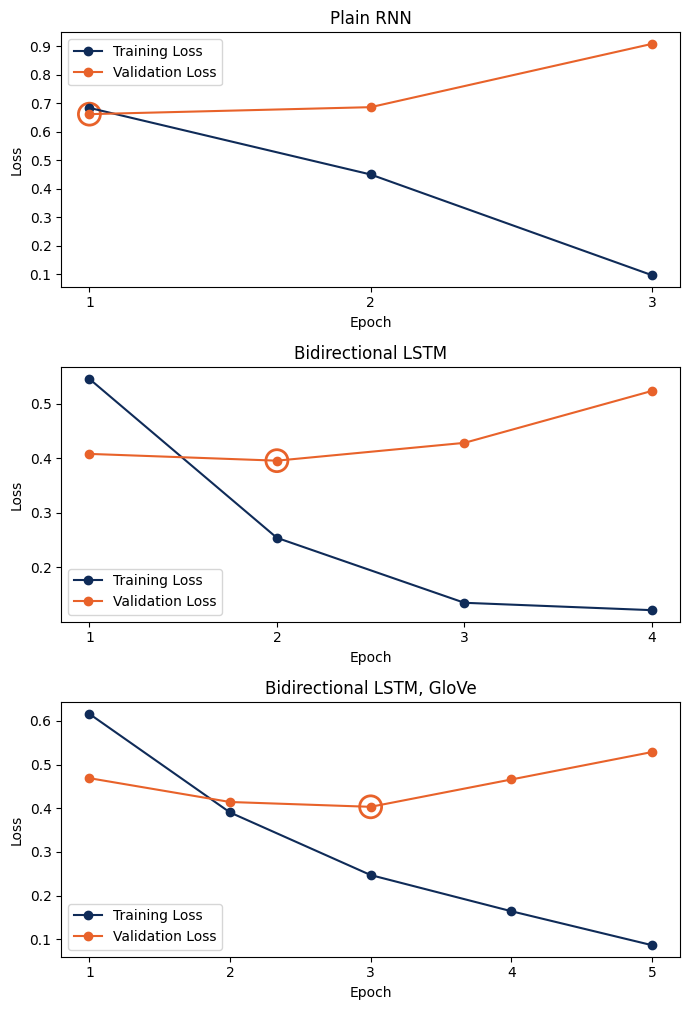

In [11]:
def plot_loss_curves(histories):
    fig, axes = plt.subplots(len(histories), 1, figsize=(7, 3.4 * len(histories)), squeeze=False)
    for ax, (name, history) in zip(axes[:, 0], histories.items()):
        epochs = range(1, len(history["loss"]) + 1)
        best = int(np.argmin(history["val_loss"]))
        ax.plot(epochs, history["loss"], color="#0F2B58", marker="o", label="Training Loss")
        ax.plot(epochs, history["val_loss"], color="#E8622A", marker="o", label="Validation Loss")
        ax.scatter(best + 1, history["val_loss"][best], s=250, facecolors="none", edgecolors="#E8622A",
                   linewidths=2)
        ax.set_title(name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_xticks(list(epochs))
        ax.legend(loc="best")
    plt.tight_layout()
    plt.show()

plot_loss_curves(histories)

The plain RNN is the least stable of the three, and its result changes most from one run to another. A validation loss close to 0.693, the loss of a probability of 0.5, means that it has learned little.

## 6. Evaluating the Networks on the Test Reviews

`scores()` returns the accuracy and the macro F1 of predicted labels against the actual labels.

The baseline, a logistic regression on the TF-IDF values of the 10,000 most frequent terms, and the three networks are scored on the 1,500 test reviews:

In [12]:
def scores(y_true, y_pred):
    return {"accuracy": round(accuracy_score(y_true, y_pred), 3),
            "macro F1": round(f1_score(y_true, y_pred, average="macro"), 3)}

tfidf = TfidfVectorizer(max_features=VOCAB_SIZE)
baseline = LogisticRegression(max_iter=1000)
baseline.fit(tfidf.fit_transform(texts_train), y_train)

predictions = {"Logistic Regression, TF-IDF": baseline.predict(tfidf.transform(texts_test))}
for name, model in networks.items():
    predictions[name] = model.predict(X_test, verbose=0).argmax(axis=1)
results = pd.DataFrame({name: scores(y_test, predicted) for name, predicted in predictions.items()}).T
results

,accuracy,macro F1
"Logistic Regression, TF-IDF",0.879,0.879
Plain RNN,0.611,0.611
Bidirectional LSTM,0.831,0.829
"Bidirectional LSTM, GloVe",0.855,0.855


`plot_scores()` plots the accuracy beside the macro F1 of each model:

- `results`: a table with one row for each model and the columns `accuracy` and `macro F1`.

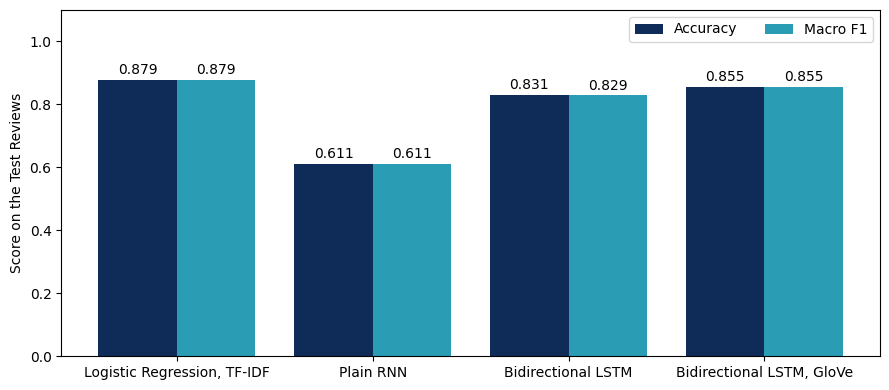

In [13]:
def plot_scores(results):
    positions = np.arange(len(results))
    fig, ax = plt.subplots(figsize=(9, 4))
    for offset, column, label, color in ((-0.2, "accuracy", "Accuracy", "#0F2B58"), (0.2, "macro F1", "Macro F1", "#2A9DB5")):
        bars = ax.bar(positions + offset, results[column], width=0.4, color=color, label=label)
        ax.bar_label(bars, fmt="%.3f", padding=2)
    ax.set_xticks(positions, results.index)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("Score on the Test Reviews")
    ax.legend(loc="upper right", ncol=2)
    plt.tight_layout()
    plt.show()

plot_scores(results)

All 3 networks should stay below the baseline, the bidirectional LSTM with GloVe vectors closest at about 0.855. With 7,000 training reviews, the GloVe vectors, learned from a much larger corpus, narrow the gap.

## 7. Attention Weights with NumPy

This section calculates one step of attention in a translation model, which the classifiers above do not use:

$$\text{score}_i = s \cdot h_i \qquad \alpha_i = \frac{e^{\text{score}_i}}{\sum_j e^{\text{score}_j}} \qquad c = \sum_i \alpha_i h_i$$

$s$ is the decoder state, $h_i$ the encoder state of token $i$, $\alpha_i$ its attention weight, $c$ the new context vector, and $j$ runs over every input token.

`attention()` returns the scores, the attention weights, and the context vector:

- `decoder_state`: the decoder state $s$, for example `np.array([1.0, 1.0])`.

- `encoder_states`: one encoder state $h_i$ for each input token, one per row.

The step generates `froid` in the translation of `the weather is cold` into `il fait froid`, with constructed encoder states of 2 values. The total of the weights, the context vector, and the score and weight of each token are displayed:

In [14]:
def attention(decoder_state, encoder_states):
    attention_scores = encoder_states @ decoder_state
    weights = np.exp(attention_scores) / np.exp(attention_scores).sum()
    context = weights @ encoder_states
    return attention_scores, weights, context

tokens = ["the", "weather", "is", "cold"]
encoder_states = np.array([[0.5, 0.0], [1.5, 1.0], [0.5, 0.5], [1.5, 1.5]])
decoder_state = np.array([1.0, 1.0])

attention_scores, weights, context = attention(decoder_state, encoder_states)
print("sum of the weights:", round(float(weights.sum()), 3))
print("context vector:", context.round(3))
pd.DataFrame({"token": tokens, "score": attention_scores, "attention weight": weights.round(3)})

sum of the weights: 1.0
context vector: [1.381 1.192]


,token,score,attention weight
0,the,0.5,0.045
1,weather,2.5,0.333
2,is,1.0,0.074
3,cold,3.0,0.548


## 8. Reviews the Network Gets Wrong

`confident_errors()` returns the reviews that a network labels incorrectly with the highest probability. It shows the actual label, the probability of the predicted label, and the first 300 characters:

- `model`: a trained network.

- `X`, `y`, `texts`: the word indices, the labels, and the texts of the reviews, for example `X_test`, `y_test`, and `texts_test`.

- `k`: the number of reviews, for example `3`.

The network with the highest validation accuracy is selected, and its 3 most confident errors on the test reviews are displayed:

In [15]:
def confident_errors(model, X, y, texts, k=3):
    probabilities = model.predict(X, verbose=0)
    predicted = probabilities.argmax(axis=1)
    wrong = np.where(predicted != y)[0]
    order = wrong[np.argsort(-probabilities[wrong].max(axis=1))][:k]
    return pd.DataFrame({
        "actual label": [LABELS[y[i]] for i in order],
        "probability": probabilities[order].max(axis=1).round(3),
        "review": [texts[i][:300] for i in order],
    })

best_name = max(val_accuracy, key=val_accuracy.get)
print("selected:", best_name)
errors = confident_errors(networks[best_name], X_test, y_test, texts_test)
errors.style.format({"probability": "{:.3f}"}).set_properties(subset=["review"], **{"text-align": "left"})

selected: Bidirectional LSTM, GloVe


,actual label,probability,review
0,positive,0.997,"I've read some terrible things about this film, so I was prepared for the worst. ""Confusing. Muddled. Horribly structured."" While there may be merit to some of these accusations, this film was nowhere near as horrific as your average DVD programmer. In fact, it actually had aspirations. It attempted"
1,positive,0.993,"Yes, some people have said that this movie was a waste of money, but i'm the kind of die hard dragon/world-ending/holy crap action movie fan. But if you take it from my stand point this movie had some of the best action sences were pretty dang good. But its that kind of movie that everything just f"
2,positive,0.988,"Above-average film and acting partly spoiled by its completely predictable story line. Even the music is chosen so that the words fit the action every time. A scent of ""Pleasantville"" camp hangs around this flick. As a period piece, it's more accurate than not. Its depiction of the tragedy of compan"


These should be positive reviews that open with criticism, quoted from others or from the reviewer, before the reviewer's own judgment.

## 9. A Classifier That Takes Raw Text

`text_classifier()` joins a new `TextVectorization` layer and a trained network into one model that takes raw text, the form needed for inference:

- `model`: a trained network.

- `vocabulary`: the vocabulary of the adapted `TextVectorization` layer, passed to the new layer so that the saved model contains it.

Files saved in Colab are deleted when the runtime ends, so download `review_classifier.keras` from the Files panel to keep it.

The selected network is joined, saved, and reloaded, and the reloaded model is checked against the network on the first 50 test reviews:

In [16]:
def text_classifier(model, vocabulary):
    text_layer = layers.TextVectorization(output_sequence_length=SEQUENCE_LENGTH, vocabulary=vocabulary)
    return keras.Sequential([keras.Input(shape=(), dtype="string"), text_layer, model])

classifier = text_classifier(networks[best_name], vocabulary)
classifier.save("review_classifier.keras")

loaded_classifier = keras.models.load_model("review_classifier.keras")
from_text = loaded_classifier.predict(tf.constant(list(texts_test[:50])), verbose=0)
from_indices = networks[best_name].predict(X_test[:50], verbose=0)
print("same probabilities after reloading:", np.allclose(from_text, from_indices, atol=1e-5))

same probabilities after reloading: True


## 10. Predicting the Sentiment of New Reviews

`predict_reviews()` returns the predicted label of each review and its probability, the larger of the two softmax outputs:

- `texts`: a list of reviews.

- `model`: a model that takes raw text, such as `loaded_classifier`.

The predictions for 5 sample reviews, written for this lab and not taken from the dataset, are displayed:

In [17]:
def predict_reviews(texts, model):
    probabilities = model.predict(tf.constant(texts), verbose=0)
    return pd.DataFrame({
        "review": texts,
        "label": [LABELS[i] for i in probabilities.argmax(axis=1)],
        "probability": probabilities.max(axis=1).round(3),
    })

sample_reviews = [
    "A clever and funny script, and the two leads are a joy to watch.",
    "I wanted to like it, but the dialogue is flat and the ending makes no sense.",
    "Not the worst film of the year, but close.",
    "The film was good, not bad.",
    "The film was bad, not good.",
]
predict_reviews(sample_reviews, loaded_classifier)

,review,label,probability
0,"A clever and funny script, and the two leads are a joy to watch.",positive,0.944
1,"I wanted to like it, but the dialogue is flat and the ending makes no sense.",positive,0.504
2,"Not the worst film of the year, but close.",negative,0.973
3,"The film was good, not bad.",negative,0.974
4,"The film was bad, not good.",negative,0.966


A probability close to 0.5 means that the network is uncertain between the two labels.

The last 2 sample reviews contain the same words in a different order, so their probabilities should differ.

7,000 training reviews may not be enough to learn how `not` changes the word that follows.

Replace the placeholder text of `custom_review` with any review, then run the cell to see its prediction:

In [18]:
custom_review = "Replace this text with a review."
predict_reviews([custom_review], loaded_classifier)

,review,label,probability
0,Replace this text with a review.,negative,0.81
